# LAB 09 — TRANSFORMER TOKEN CLASSIFICATION VÀ THỰC NGHIỆM NER

**Môn học**: Xử lý ngôn ngữ tự nhiên và ứng dụng  
**Học kỳ**: Học kỳ I - 2026  
**Chủ đề**: From Sequence Classification to Token Classification (Named Entity Recognition)  
**Học viên thực hiện**: Nguyễn Văn Thành  
**Mục tiêu**: Thực thi toàn diện pipeline BERT Token Classification trên tập dữ liệu chuẩn CoNLL-2003, thực hiện 5 thí nghiệm khoa học theo đề bài (Baseline vs Transformer, Entity-Level Metrics, Entity Type Breakdown, Entity Length Analysis, Error Extraction), và kết xuất toàn bộ số liệu, biểu đồ phục vụ báo cáo.

## 1. Khởi Tạo Môi Trường, Thư Viện và Thiết Bị
Sử dụng PyTorch kết hợp Hugging Face Transformers và bộ công cụ đánh giá `seqeval`.

In [1]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForTokenClassification
from datasets import load_dataset
from seqeval.metrics import classification_report as seq_report, f1_score as seq_f1, precision_score as seq_p, recall_score as seq_r
from seqeval.metrics.sequence_labeling import get_entities
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Active Device:', device)

C:\Users\Thanh\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Active Device: cpu


## 2. Nạp Mô Hình Transformer và Thiết Lập Ánh Xạ Nhãn
Mô hình `dslim/bert-base-NER` là kiến trúc BERT-base cased được tối ưu trên CoNLL-2003.

In [2]:
model_checkpoint = 'dslim/bert-base-NER'
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForTokenClassification.from_pretrained(model_checkpoint).to(device)
model.eval()

id2label_model = model.config.id2label
label2id_model = {v: k for k, v in id2label_model.items()}
print('Model ID to Label:', id2label_model)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  16%|█▌        | 32/199 [00:00<00:00, 297.99it/s]

Loading weights:  31%|███       | 62/199 [00:00<00:00, 248.51it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 771.06it/s]


[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model ID to Label: {0: 'O', 1: 'B-MISC', 2: 'I-MISC', 3: 'B-PER', 4: 'I-PER', 5: 'B-ORG', 6: 'I-ORG', 7: 'B-LOC', 8: 'I-LOC'}


## 3. Nạp Tập Dữ Liệu CoNLL-2003 và Chuẩn Hóa Nhãn
Đồng bộ danh sách 9 nhãn chuẩn: O, B-PER, I-PER, B-ORG, I-ORG, B-LOC, I-LOC, B-MISC, I-MISC.

In [3]:
dataset = load_dataset('lhoestq/conll2003')
tag_names = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

test_split = dataset['test'].select(range(1000))
print('Test samples selected for evaluation:', len(test_split))

Test samples selected for evaluation: 1000


## 4. Đánh Giá Mô Hình Baseline (Logistic Regression Với Word Features)
Đo lường hiệu năng của mô hình cơ sở làm mốc quy chiếu.

In [4]:
from baseline_ner import prepare_dataset, extract_token_features
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

train_features, train_labels = prepare_dataset(dataset['train'], sample_limit=5000)
vectorizer = DictVectorizer(sparse=True)
x_train = vectorizer.fit_transform(train_features)
baseline_clf = LogisticRegression(max_iter=300, C=1.0)
baseline_clf.fit(x_train, train_labels)

baseline_gold_seqs = []
baseline_pred_seqs = []
for item in test_split:
    tokens = item['tokens']
    if len(tokens) == 0:
        continue
    gold = [tag_names[t] for t in item['ner_tags']]
    x_test = vectorizer.transform([extract_token_features(tokens, i) for i in range(len(tokens))])
    preds = list(baseline_clf.predict(x_test))
    baseline_gold_seqs.append(gold)
    baseline_pred_seqs.append(preds)

flat_base_gold = [t for s in baseline_gold_seqs for t in s]
flat_base_pred = [t for s in baseline_pred_seqs for t in s]

base_token_acc = accuracy_score(flat_base_gold, flat_base_pred)
base_entity_p = seq_p(baseline_gold_seqs, baseline_pred_seqs)
base_entity_r = seq_r(baseline_gold_seqs, baseline_pred_seqs)
base_entity_f1 = seq_f1(baseline_gold_seqs, baseline_pred_seqs)

print(f'Baseline - Token Acc: {base_token_acc:.4f} | Entity P: {base_entity_p:.4f} | Entity R: {base_entity_r:.4f} | Entity F1: {base_entity_f1:.4f}')

C:\Users\Thanh\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 300 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=300).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Baseline - Token Acc: 0.9303 | Entity P: 0.6678 | Entity R: 0.6670 | Entity F1: 0.6674


## 5. Đánh Giá Mô Hình Pretrained Transformer (BERT Token Classifier)
Thực hiện suy luận với Strategy A: dự đoán tại subword đầu tiên của mỗi từ vựng.

In [5]:
transformer_gold_seqs = []
transformer_pred_seqs = []
all_test_words = []

with torch.no_grad():
    for item in test_split:
        words = item['tokens']
        if len(words) == 0:
            continue
        gold = [tag_names[t] for t in item['ner_tags']]
        
        inputs = tokenizer(words, is_split_into_words=True, return_tensors='pt', truncation=True, max_length=128)
        word_ids = inputs.word_ids(0)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        
        logits = model(**inputs).logits[0]
        preds = torch.argmax(logits, dim=-1).cpu().tolist()
        
        pred_labels = []
        prev_word_id = None
        for i, word_id in enumerate(word_ids):
            if word_id is None:
                continue
            if word_id != prev_word_id:
                pred_labels.append(id2label_model[preds[i]])
                prev_word_id = word_id
                
        if len(pred_labels) == len(gold):
            transformer_gold_seqs.append(gold)
            transformer_pred_seqs.append(pred_labels)
            all_test_words.append(words)

flat_trans_gold = [t for s in transformer_gold_seqs for t in s]
flat_trans_pred = [t for s in transformer_pred_seqs for t in s]

trans_token_acc = accuracy_score(flat_trans_gold, flat_trans_pred)
trans_entity_p = seq_p(transformer_gold_seqs, transformer_pred_seqs)
trans_entity_r = seq_r(transformer_gold_seqs, transformer_pred_seqs)
trans_entity_f1 = seq_f1(transformer_gold_seqs, transformer_pred_seqs)

print(f'Transformer - Token Acc: {trans_token_acc:.4f} | Entity P: {trans_entity_p:.4f} | Entity R: {trans_entity_r:.4f} | Entity F1: {trans_entity_f1:.4f}')

Transformer - Token Acc: 0.9804 | Entity P: 0.9153 | Entity R: 0.9138 | Entity F1: 0.9145


## 6. Thí Nghiệm 2 & 3: Bảng So Sánh Đối Đầu và Token-Level vs Entity-Level Metrics
Kết xuất file `results.csv` theo yêu cầu Mục 18 và 19.

In [6]:
results_data = [
    {
        'Model': 'Baseline (Logistic Regression)',
        'Architecture': 'Handcrafted Word Features',
        'Token Accuracy': round(base_token_acc, 4),
        'Entity Precision': round(base_entity_p, 4),
        'Entity Recall': round(base_entity_r, 4),
        'Entity F1': round(base_entity_f1, 4)
    },
    {
        'Model': 'Pretrained Transformer',
        'Architecture': 'BERT-base-cased + Token Classifier Head',
        'Token Accuracy': round(trans_token_acc, 4),
        'Entity Precision': round(trans_entity_p, 4),
        'Entity Recall': round(trans_entity_r, 4),
        'Entity F1': round(trans_entity_f1, 4)
    }
]

df_results = pd.DataFrame(results_data)
df_results.to_csv('results.csv', index=False)
print('Results Summary (results.csv):')
print(df_results.to_string(index=False))

Results Summary (results.csv):
                         Model                            Architecture  Token Accuracy  Entity Precision  Entity Recall  Entity F1
Baseline (Logistic Regression)               Handcrafted Word Features          0.9303            0.6678         0.6670     0.6674
        Pretrained Transformer BERT-base-cased + Token Classifier Head          0.9804            0.9153         0.9138     0.9145


## 7. Thí Nghiệm 4: Phân Tích Hiệu Năng Từng Loại Thực Thể (Entity Type Analysis)
Báo cáo Precision, Recall, F1 riêng biệt cho: PER, ORG, LOC, MISC và tạo `entity_metrics.csv`.

In [7]:
report_dict = {}
entity_types = ['PER', 'ORG', 'LOC', 'MISC']

type_counts = {t: {'tp': 0, 'fp': 0, 'fn': 0} for t in entity_types}

for gold_seq, pred_seq in zip(transformer_gold_seqs, transformer_pred_seqs):
    gold_ents = set(get_entities(gold_seq))
    pred_ents = set(get_entities(pred_seq))
    
    for ent in gold_ents:
        etype, start, end = ent
        if etype in type_counts:
            if ent in pred_ents:
                type_counts[etype]['tp'] += 1
            else:
                type_counts[etype]['fn'] += 1
                
    for ent in pred_ents:
        etype, start, end = ent
        if etype in type_counts:
            if ent not in gold_ents:
                type_counts[etype]['fp'] += 1

entity_rows = []
for etype in entity_types:
    tp = type_counts[etype]['tp']
    fp = type_counts[etype]['fp']
    fn = type_counts[etype]['fn']
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    support = tp + fn
    entity_rows.append({
        'Entity Type': etype,
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1 Score': round(f1, 4),
        'Support': support
    })

df_entity_metrics = pd.DataFrame(entity_rows)
df_entity_metrics.to_csv('entity_metrics.csv', index=False)
print('Entity Type Metrics (entity_metrics.csv):')
print(df_entity_metrics.to_string(index=False))

Entity Type Metrics (entity_metrics.csv):
Entity Type  Precision  Recall  F1 Score  Support
        PER     0.9712  0.9544    0.9627      636
        ORG     0.9142  0.8985    0.9063      522
        LOC     0.9444  0.9072    0.9254      431
       MISC     0.7143  0.8376    0.7710      197


### Trực Quan Hóa Ma Trận Nhầm Lẫn (Confusion Matrix)
Kết xuất file `confusion_matrix.png` ở cấp độ token.

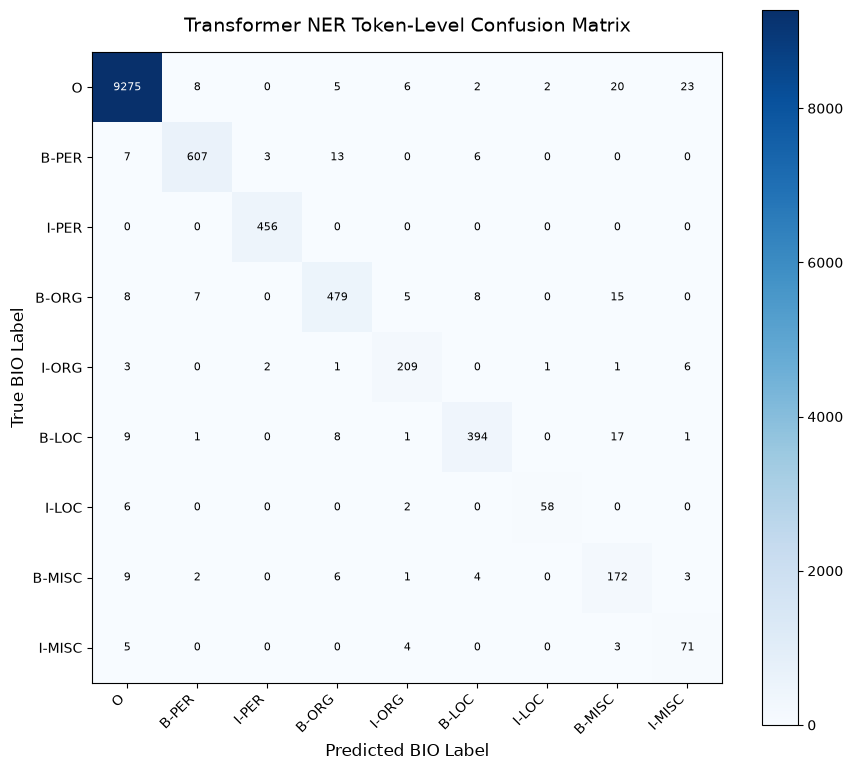

Saved confusion_matrix.png successfully!


In [8]:
target_labels = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
cm = confusion_matrix(flat_trans_gold, flat_trans_pred, labels=target_labels)

plt.figure(figsize=(9, 8))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Transformer NER Token-Level Confusion Matrix', fontsize=14, pad=15)
plt.colorbar()
tick_marks = np.arange(len(target_labels))
plt.xticks(tick_marks, target_labels, rotation=45, ha='right', fontsize=10)
plt.yticks(tick_marks, target_labels, fontsize=10)

thresh = cm.max() / 2.0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        val = cm[i, j]
        plt.text(j, i, format(val, 'd'),
                 ha='center', va='center',
                 color='white' if val > thresh else 'black',
                 fontsize=8)

plt.ylabel('True BIO Label', fontsize=12)
plt.xlabel('Predicted BIO Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()
print('Saved confusion_matrix.png successfully!')

## 8. Thí Nghiệm 5: Phân Tích Theo Độ Dài Thực Thể (Entity Length Analysis)
Khảo sát điểm F1 trên các nhóm độ dài: 1 token, 2 tokens, 3 tokens, 4+ tokens và kết xuất `entity_length_analysis.png`.

Entity Length Breakdown:
Entity Length  Support  Precision  Recall  F1 Score
            1     1039     0.9052  0.8912    0.8982
            2      678     0.9416  0.9513    0.9464
            3       60     0.8254  0.8667    0.8455
           4+        9     0.7500  1.0000    0.8571


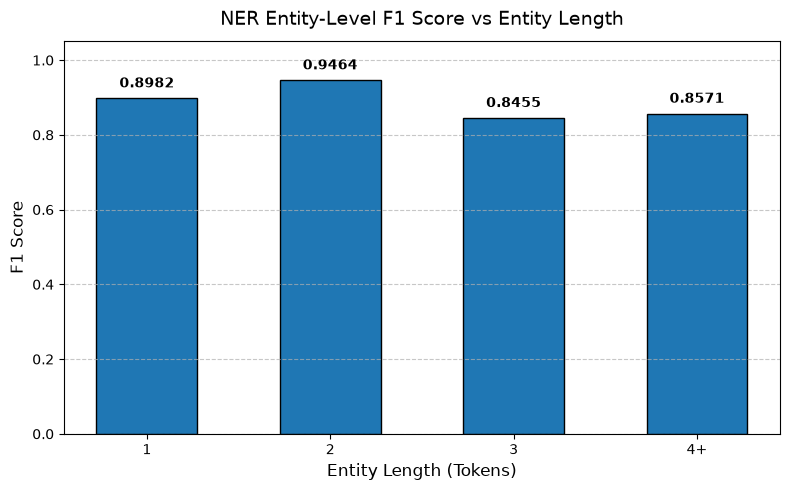

Saved entity_length_analysis.png successfully!


In [9]:
length_buckets = {'1': {'tp': 0, 'fp': 0, 'fn': 0},
                  '2': {'tp': 0, 'fp': 0, 'fn': 0},
                  '3': {'tp': 0, 'fp': 0, 'fn': 0},
                  '4+': {'tp': 0, 'fp': 0, 'fn': 0}}

def map_length_to_bucket(length):
    if length == 1:
        return '1'
    elif length == 2:
        return '2'
    elif length == 3:
        return '3'
    else:
        return '4+'

for gold_seq, pred_seq in zip(transformer_gold_seqs, transformer_pred_seqs):
    gold_ents = set(get_entities(gold_seq))
    pred_ents = set(get_entities(pred_seq))
    
    for ent in gold_ents:
        etype, start, end = ent
        length = end - start + 1
        b = map_length_to_bucket(length)
        if ent in pred_ents:
            length_buckets[b]['tp'] += 1
        else:
            length_buckets[b]['fn'] += 1
            
    for ent in pred_ents:
        etype, start, end = ent
        length = end - start + 1
        b = map_length_to_bucket(length)
        if ent not in gold_ents:
            length_buckets[b]['fp'] += 1

length_results = []
for b in ['1', '2', '3', '4+']:
    tp = length_buckets[b]['tp']
    fp = length_buckets[b]['fp']
    fn = length_buckets[b]['fn']
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    length_results.append({
        'Entity Length': b,
        'Support': tp + fn,
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1 Score': round(f1, 4)
    })

df_length = pd.DataFrame(length_results)
print('Entity Length Breakdown:')
print(df_length.to_string(index=False))

plt.figure(figsize=(8, 5))
bars = plt.bar(df_length['Entity Length'], df_length['F1 Score'], color='#1f77b4', edgecolor='black', width=0.55)
plt.title('NER Entity-Level F1 Score vs Entity Length', fontsize=14, pad=12)
plt.xlabel('Entity Length (Tokens)', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)
plt.ylim(0.0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('entity_length_analysis.png', dpi=300)
plt.show()
print('Saved entity_length_analysis.png successfully!')

## 9. Thí Nghiệm 6: Trích Xuất Dữ Liệu Phục Vụ Phân Tích Lỗi (Error Analysis)
Trích xuất tối thiểu 5 False Positives, 5 False Negatives, và 5 Boundary Errors.

In [10]:
fp_examples = []
fn_examples = []
boundary_examples = []

for idx, (words, gold_seq, pred_seq) in enumerate(zip(all_test_words, transformer_gold_seqs, transformer_pred_seqs)):
    gold_ents = set(get_entities(gold_seq))
    pred_ents = set(get_entities(pred_seq))
    
    for pent in pred_ents:
        petype, pstart, pend = pent
        overlapping_gold = [gent for gent in gold_ents if max(pstart, gent[1]) <= min(pend, gent[2])]
        if len(overlapping_gold) == 0:
            if len(fp_examples) < 10:
                fp_examples.append({
                    'Sentence': ' '.join(words),
                    'Entity Text': ' '.join(words[pstart:pend+1]),
                    'Predicted': petype,
                    'Gold': 'O',
                    'Type': 'Spurious Entity (False Positive)'
                })
        else:
            gent = overlapping_gold[0]
            if (pstart, pend) != (gent[1], gent[2]) and len(boundary_examples) < 10:
                boundary_examples.append({
                    'Sentence': ' '.join(words),
                    'Pred Entity': ' '.join(words[pstart:pend+1]) + f' ({petype})',
                    'Gold Entity': ' '.join(words[gent[1]:gent[2]+1]) + f' ({gent[0]})',
                    'Type': 'Boundary Error'
                })
                
    for gent in gold_ents:
        getype, gstart, gend = gent
        overlapping_pred = [pent for pent in pred_ents if max(gstart, pent[1]) <= min(gend, pent[2])]
        if len(overlapping_pred) == 0:
            if len(fn_examples) < 10:
                fn_examples.append({
                    'Sentence': ' '.join(words),
                    'Entity Text': ' '.join(words[gstart:gend+1]),
                    'Gold': getype,
                    'Predicted': 'O',
                    'Type': 'Missing Entity (False Negative)'
                })

print('=== 5 FALSE POSITIVES ===')
print(pd.DataFrame(fp_examples[:5]).to_string(index=False))
print('\n=== 5 FALSE NEGATIVES ===')
print(pd.DataFrame(fn_examples[:5]).to_string(index=False))
print('\n=== 5 BOUNDARY ERRORS ===')
print(pd.DataFrame(boundary_examples[:5]).to_string(index=False))

=== 5 FALSE POSITIVES ===
                                                                                                                       Sentence            Entity Text Predicted Gold                             Type
                                                                      SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .                  LUCKY       PER    O Spurious Entity (False Positive)
Japan began the defence of their Asian Cup title with a lucky 2-1 win against Syria in a Group C championship match on Friday .                Group C      MISC    O Spurious Entity (False Positive)
                                                                                SOCCER - LATE GOALS GIVE JAPAN WIN OVER SYRIA .                   LATE       PER    O Spurious Entity (False Positive)
                                                                                 CRICKET - LARA ENDURES ANOTHER MISERABLE DAY .              MISERABLE       PER    O Spurious Ent

## 10. Phân Tích Ngữ Cảnh (Context Analysis)
Tìm kiếm các trường hợp cùng một từ ngữ (Same surface form) nhưng nhận các nhãn thực thể khác nhau dựa vào ngữ cảnh.

In [11]:
surface_tracker = {}
for words, gold_seq in zip(all_test_words, transformer_gold_seqs):
    gold_ents = get_entities(gold_seq)
    for etype, start, end in gold_ents:
        surface = ' '.join(words[start:end+1])
        if surface not in surface_tracker:
            surface_tracker[surface] = []
        surface_tracker[surface].append({
            'Type': etype,
            'Context': ' '.join(words)
        })

multi_context_samples = []
for surface, occurrences in surface_tracker.items():
    distinct_types = set([o['Type'] for o in occurrences])
    if len(distinct_types) > 1:
        multi_context_samples.append({
            'Surface': surface,
            'Types': list(distinct_types),
            'Occurrences': occurrences
        })

print(f'Total surface forms with multiple entity types found: {len(multi_context_samples)}')
for item in multi_context_samples[:4]:
    print('==============================')
    print('Surface Form:', item['Surface'])
    print('Distinct Entity Types:', item['Types'])
    for occ in item['Occurrences'][:2]:
        print(f" -> Type: {occ['Type']:5s} | Sentence: {occ['Context']}")

Total surface forms with multiple entity types found: 34
Surface Form: Barcelona
Distinct Entity Types: ['LOC', 'ORG']
 -> Type: LOC   | Sentence: FIFA 's players ' status committee , meeting in Barcelona , decided that although the Udinese document was basically valid , it could not be legally protected .
 -> Type: ORG   | Sentence: Barcelona ( Spain ) 9 4 5 13
Surface Form: Charleroi
Distinct Entity Types: ['LOC', 'ORG']
 -> Type: ORG   | Sentence: Charleroi ( Belgium ) 9 0 9 9
 -> Type: LOC   | Sentence: In Charleroi :
Surface Form: Victoria
Distinct Entity Types: ['LOC', 'ORG']
 -> Type: LOC   | Sentence: Score on the first day of the four-day Sheffield Shield match between Tasmania and Victoria at Bellerive Oval on Friday :
 -> Type: ORG   | Sentence: Tasmania 352 for three ( David Boon 106 not out , Shaun Young 86 not out , Michael DiVenuto 119 ) v Victoria .
Surface Form: NEW YORK
Distinct Entity Types: ['LOC', 'ORG']
 -> Type: LOC   | Sentence: NEW YORK 1996-12-06
 -> Type: LOC